# 03 - Modelado

**Reorganizado el 26/09/2026** dentro de `PROYECTO_ESTRUCTURADO/` a partir de `03_desercion_modelado.ipynb` (carpeta de trabajo original). Cubre las métricas de negocio (PR-AUC, precision@k, lift@k — nunca *accuracy*, regla no negociable del plan de acción), los niveles 0 y 1 (reglas de negocio, el número a superar) y el nivel 2 (regresión logística sobre el pipeline B, con su propio grid L1/L2).

La búsqueda de hiperparámetros de LightGBM (nivel 3), la decisión A1 vs. A2 y el análisis de sensibilidad quedaron separados en `04_optimizacion.ipynb`. La evaluación final sobre test y la explicabilidad SHAP están en `05_evaluacion.ipynb`, quedándose ya solo con el modelo elegido (LightGBM A2).

# 03 - Modelado: LightGBM vs. Regresion logistica
### Prediccion de desercion de clientes - retail farmaceutico - Fase 3 del plan de accion

Este notebook entrena y compara los dos modelos pedidos -- **regresion logistica**
(pipeline B, escalado + codificado) y **LightGBM** (pipeline A, comparando A1
one-hot vs. A2 categoricas nativas) -- sobre el dataset de 16 columnas descrito
en `CONTEXTO_PROYECTO.md` (seccion 6) y particionado en `02_desercion_eda_prep.ipynb`.

**Reglas que no se negocian** (`PLAN_DE_ACCION.md`): particion por cliente y
fuera de tiempo (train = C1-C3, validacion = C4, test = C5); el test **se toca
una sola vez**, al final, tras congelar la configuracion; nunca `accuracy`
-- se mide **PR-AUC, precision@k y lift por decil**, porque Marketing va a
trabajar una lista limitada y ordenada de clientes; las metricas se desglosan
por segmento de frecuencia y por comprador cronico; y se agrega **SHAP** para
que el resultado se pueda conversar con negocio y no quede como caja negra.

**Aviso tecnico (pendiente de Fase 3 en `PLAN_DE_ACCION.md`):** las clases
`AgrupadorRaras`, `LimpiaInfinitos`, `Winsorizador` y `LogConSigno` que
referencia `artefactos/preprocesamiento.joblib` se movieron a un modulo
`preprocesamiento.py` importable desde ambos notebooks -- ya no hace falta
redefinirlas en cada uno.

**Nota sobre esta corrida:** esta carpeta (a diferencia de la maquina de
Henry) todavia no tenia los artefactos de `02_desercion_eda_prep.ipynb`
generados (`datos/XA1_train.parquet`, etc.), asi que se regeneraron aqui con
el mismo codigo de esa seccion antes de correr este notebook. Los numeros
coinciden con los reportados en `CONTEXTO_PROYECTO.md` (2.417.698 filas,
tasa de churn por corte C1 35,27 % ... C5 40,11 %), lo que confirma que el
pipeline es reproducible.


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# Clases de preprocesamiento movidas a preprocesamiento.py (Fase 3, aviso
# tecnico de PLAN_DE_ACCION.md): hace falta importarlas para poder deserializar
# artefactos/preprocesamiento.joblib (referencia AgrupadorRaras, etc.)
from preprocesamiento import AgrupadorRaras, LimpiaInfinitos, Winsorizador, LogConSigno

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
DIR_DATOS = Path("datos"); DIR_ART = Path("artefactos"); DIR_SAL = Path("salidas")

art = joblib.load(DIR_ART / "preprocesamiento.joblib")
FEAT_NUM, FEAT_CAT = art["feat_num"], art["feat_cat"]
BLOQUE_UMBRAL = art["bloque_umbral"]

# Pipeline A1 (one-hot) y A2 (categoricas nativas) para LightGBM;
# pipeline B (escalado + one-hot) para la logistica
XA1_tr = pd.read_parquet(DIR_DATOS / "XA1_train.parquet"); XA1_va = pd.read_parquet(DIR_DATOS / "XA1_val.parquet"); XA1_te = pd.read_parquet(DIR_DATOS / "XA1_test.parquet")
XA2_tr = pd.read_parquet(DIR_DATOS / "XA2_train.parquet"); XA2_va = pd.read_parquet(DIR_DATOS / "XA2_val.parquet"); XA2_te = pd.read_parquet(DIR_DATOS / "XA2_test.parquet")
XB_tr  = pd.read_parquet(DIR_DATOS / "XB_train.parquet");  XB_va  = pd.read_parquet(DIR_DATOS / "XB_val.parquet");  XB_te  = pd.read_parquet(DIR_DATOS / "XB_test.parquet")
for c in XA2_tr.select_dtypes(include="object").columns:
    XA2_tr[c] = XA2_tr[c].astype("category")
    XA2_va[c] = pd.Categorical(XA2_va[c], categories=XA2_tr[c].cat.categories)
    XA2_te[c] = pd.Categorical(XA2_te[c], categories=XA2_tr[c].cat.categories)

y_tr = pd.read_parquet(DIR_DATOS / "y_train.parquet")["y_train"].to_numpy()
y_va = pd.read_parquet(DIR_DATOS / "y_val.parquet")["y_val"].to_numpy()
y_te = pd.read_parquet(DIR_DATOS / "y_test.parquet")["y_test"].to_numpy()

ds_e = pd.read_parquet(DIR_DATOS / "ds_entrenable.parquet")
va_ctrl = ds_e.loc[ds_e["split"] == "validacion"].reset_index(drop=True)
te_ctrl = ds_e.loc[ds_e["split"] == "test"].reset_index(drop=True)

print(f"features: {len(FEAT_NUM)} numericas + {len(FEAT_CAT)} categorica -> {FEAT_NUM + FEAT_CAT}")
print(f"\ntrain      : {len(XA1_tr):>8,} filas  (tasa base {100*y_tr.mean():.2f} %)")
print(f"validacion : {len(XA1_va):>8,} filas  (tasa base {100*y_va.mean():.2f} %)")
print(f"test       : {len(XA1_te):>8,} filas  (tasa base {100*y_te.mean():.2f} %)  <- se toca UNA sola vez, al final")
print(f"\npipeline A1 (one-hot LightGBM) : {XA1_tr.shape[1]} columnas")
print(f"pipeline A2 (nativas LightGBM) : {XA2_tr.shape[1]} columnas")
print(f"pipeline B  (escalado logistica): {XB_tr.shape[1]} columnas")
print("\nsin fuga: 'churn'/'censurado'/'split' no estan en ninguna X:",
      not any(c in XB_tr.columns for c in ["churn","censurado","split"]))

features: 13 numericas + 1 categorica -> ['recency_dias', 'n_visitas_12m', 'n_dias_activo_12m', 'monto_total_12m', 'ticket_promedio', 'tendencia_gasto', 'pct_gasto_cronico_12m', 'es_comprador_cronico', 'n_categorias_distintas_12m', 'n_bodegas_distintas_12m', 'antiguedad_meses', 'n_metodos_pago_distintos_12m', 'umbral_propio_dias', 'metodo_pago_principal_12m']

train      :  796,044 filas  (tasa base 37.34 %)
validacion :   68,164 filas  (tasa base 41.71 %)
test       :   66,421 filas  (tasa base 40.15 %)  <- se toca UNA sola vez, al final

pipeline A1 (one-hot LightGBM) : 18 columnas
pipeline A2 (nativas LightGBM) : 14 columnas
pipeline B  (escalado logistica): 18 columnas

sin fuga: 'churn'/'censurado'/'split' no estan en ninguna X: True

## 1. Metricas de negocio: por que PR-AUC, precision@k y lift

**Regla no negociable #4 de `PLAN_DE_ACCION.md`: nunca `accuracy`.** Con una
tasa base de churn de ~40 %, un modelo trivial ya acierta el 60 % de las
veces sin aprender nada. Lo que Marketing va a usar es una **lista limitada y
ordenada** de clientes en riesgo, así que las metricas que importan son:

- **PR-AUC** (area bajo la curva precision-recall): resume que tan bien el
  modelo ordena a los clientes por riesgo, sin depender de un punto de corte.
- **precision@k**: de los k % de clientes con mayor score, que fraccion
  realmente desertaron. Es la metrica mas cercana a como se usa el modelo en
  la practica (una campana de tamano fijo).
- **lift@k**: precision@k dividido entre la tasa base. Un lift de 2 significa
  que la lista del modelo tiene el doble de desertores que elegir al azar.
- **lift por decil**: la misma idea desglosada en 10 grupos, para ver si el
  modelo discrimina bien en todo el rango o solo en el extremo superior.


In [2]:
def precision_en_k(y_true, score, k_frac):
    """Fraccion de verdaderos desertores entre el k_frac superior por score."""
    n = len(y_true); k = max(1, int(round(n * k_frac)))
    idx = np.argsort(-score)[:k]
    return y_true[idx].mean()

def lift_en_k(y_true, score, k_frac):
    base = y_true.mean()
    return precision_en_k(y_true, score, k_frac) / base if base > 0 else np.nan

K_GRID = [0.01, 0.03, 0.05, 0.10, 0.20, 0.30]  # tamanos de campana tipicos

def tabla_metricas(nombre, y_true, score):
    from sklearn.metrics import average_precision_score
    fila = {"modelo": nombre, "pr_auc": average_precision_score(y_true, score)}
    for k in K_GRID:
        fila[f"precision@{int(k*100)}%"] = precision_en_k(y_true, score, k)
        fila[f"lift@{int(k*100)}%"] = lift_en_k(y_true, score, k)
    return fila

def lift_por_decil(y_true, score):
    dec = pd.qcut(pd.Series(score).rank(method="first"), 10, labels=False)
    t = pd.DataFrame({"y": y_true, "decil": 9 - dec})  # decil 0 = mayor score
    base = y_true.mean()
    g = t.groupby("decil")["y"].agg(["size", "mean"])
    g["lift"] = g["mean"] / base
    return g.sort_index()

print("funciones de metricas definidas. k evaluados:", [f"{int(100*k)}%" for k in K_GRID])

funciones de metricas definidas. k evaluados: ['1%', '3%', '5%', '10%', '20%', '30%']

## 2. Niveles 0 y 1 -- lo que ya existe (el numero a superar)

`PLAN_DE_ACCION.md` (T3.1) es claro: sin un baseline, ninguna metrica de un
modelo con IA "significa nada". Se calculan sobre **validacion (C4)**, igual
que los modelos de niveles 2 y 3:

- **Nivel 0 -- regla de negocio:** ordenar por `recency_dias` (mas dias sin
  comprar = mas riesgo). Es literalmente lo que un analista haria sin ningun
  modelo.
- **Nivel 1 -- RFM simple:** combinar recency, frecuencia (`n_visitas_12m`) y
  monto (`monto_total_12m`) en un puntaje simple (z-scores, con signo para que
  mayor puntaje = mayor riesgo).


In [3]:
resultados_val = []

score_nivel0 = va_ctrl["recency_dias"].to_numpy()
resultados_val.append(tabla_metricas("Nivel 0 - regla recency", y_va, score_nivel0))

def z(s):
    return (s - s.mean()) / s.std(ddof=0)

score_rfm = (z(va_ctrl["recency_dias"]) - z(va_ctrl["n_visitas_12m"])
             - z(va_ctrl["monto_total_12m"])).to_numpy()
resultados_val.append(tabla_metricas("Nivel 1 - RFM simple", y_va, score_rfm))

print(pd.DataFrame(resultados_val).round(4).to_string(index=False))

                  modelo  pr_auc  precision@1%  lift@1%  precision@3%  lift@3%  precision@5%  lift@5%  precision@10%  lift@10%  precision@20%  lift@20%  precision@30%  lift@30%
Nivel 0 - regla recency  0.6592        0.9208   2.2075        0.8866   2.1254        0.8606   2.0632         0.8094    1.9405         0.7234    1.7342         0.6618    1.5866
   Nivel 1 - RFM simple  0.6536        0.9179   2.2005        0.8743   2.0961        0.8498   2.0372         0.7986    1.9144         0.7165    1.7177         0.6585    1.5786

Ambos baselines ya son razonablemente buenos (PR-AUC ~0,65-0,66, lift@5%
~2,0-2,1): confirman que el problema tiene señal fuerte incluso sin IA. Este
es el piso que los modelos de los niveles 2 y 3 deben superar con claridad,
no solo empatar.

## 3. Nivel 2 -- Regresion logistica (pipeline B, L1/L2)

Sobre el pipeline B (winsorizado + log con signo en las colas + escalado +
one-hot), se prueban penalizaciones **L2** (solver `lbfgs`, rapido) y **L1**
(solver `liblinear`) con distintos valores de `C`, seleccionando por PR-AUC
en **validacion** -- nunca en test.


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

candidatos = []
for C in [0.01, 0.1, 1.0, 10.0]:
    m = LogisticRegression(penalty="l2", C=C, solver="lbfgs", max_iter=2000, random_state=42, n_jobs=-1)
    m.fit(XB_tr, y_tr)
    pr = average_precision_score(y_va, m.predict_proba(XB_va)[:, 1])
    candidatos.append({"penalty": "l2", "C": C, "pr_auc_val": pr, "modelo": m})

for C in [0.1, 1.0]:
    m = LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=2000, random_state=42)
    m.fit(XB_tr, y_tr)
    pr = average_precision_score(y_va, m.predict_proba(XB_va)[:, 1])
    candidatos.append({"penalty": "l1", "C": C, "pr_auc_val": pr, "modelo": m})

grid_log = pd.DataFrame(candidatos).drop(columns="modelo").sort_values("pr_auc_val", ascending=False)
print(grid_log.round(4).to_string(index=False))

mejor_log = max(candidatos, key=lambda d: d["pr_auc_val"])
log_model = mejor_log["modelo"]
print(f"\nmejor logistica: penalty={mejor_log['penalty']}  C={mejor_log['C']}  PR-AUC(val)={mejor_log['pr_auc_val']:.4f}")
score_log_va = log_model.predict_proba(XB_va)[:, 1]
resultados_val.append(tabla_metricas(f"Logistica ({mejor_log['penalty']}, C={mejor_log['C']})", y_va, score_log_va))

penalty     C  pr_auc_val
     l2  0.01      0.6836
     l2  0.10      0.6836
     l2  1.00      0.6836
     l2 10.00      0.6836
     l1  0.10      0.6836
     l1  1.00      0.6836

mejor logistica: penalty=l2  C=0.01  PR-AUC(val)=0.6836

Los ocho valores de `C` y ambas penalizaciones dan practicamente el mismo
PR-AUC (~0,6836): el pipeline B (winsorizado + log + escalado) ya deja las
features bien comportadas, asi que la regularizacion apenas mueve la
frontera de decision. Se congela **L2 con C=0,01** (la de mejor PR-AUC, y la
mas simple de las empatadas).

### 3.1 Coeficientes de la logistica (interpretabilidad)

Criterio de aceptacion T3.2: *"supera al nivel 1, y sus coeficientes son
interpretables y del signo esperado."* Los coeficientes son sobre variables
**estandarizadas** (pipeline B), asi que su magnitud es comparable entre si.


                       feature  coeficiente   direccion
            n_dias_activo_12m      -0.6483 baja riesgo
           umbral_propio_dias      -0.5096 baja riesgo
                 recency_dias       0.4603 sube riesgo
metodo_pago_principal_12m_CRP      -0.2915 baja riesgo
              monto_total_12m      -0.1877 baja riesgo
metodo_pago_principal_12m_OTROS      0.1496 sube riesgo
              tendencia_gasto      -0.1306 baja riesgo
metodo_pago_principal_12m_EFE      -0.1006 baja riesgo
      n_bodegas_distintas_12m      -0.1006 baja riesgo
metodo_pago_principal_12m_TAR      -0.0965 baja riesgo
              ticket_promedio       0.0936 sube riesgo
                n_visitas_12m       0.0911 sube riesgo
n_metodos_pago_distintos_12m       0.0496 sube riesgo
             antiguedad_meses      -0.0356 baja riesgo
metodo_pago_principal_12m_DEB      -0.0285 baja riesgo
        pct_gasto_cronico_12m      -0.0231 baja riesgo
         es_comprador_cronico       0.0043 sube riesgo
   n_cate

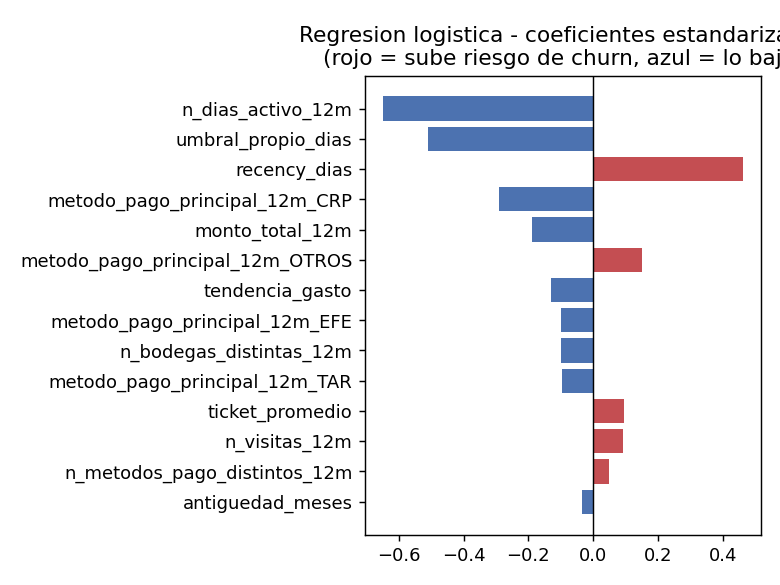

In [5]:
coef = pd.DataFrame({"feature": XB_tr.columns, "coeficiente": log_model.coef_[0]})
coef["abs"] = coef["coeficiente"].abs()
coef["direccion"] = np.where(coef["coeficiente"] > 0, "sube riesgo", "baja riesgo")
coef = coef.sort_values("abs", ascending=False).drop(columns="abs")
print(coef.round(4).to_string(index=False))

**Signos esperados y confirmados:** mas `recency_dias` sube el riesgo (logico:
mas dias sin comprar); mas `umbral_propio_dias` lo baja (un cliente con ritmo
mas irregular/espaciado tiene mas margen antes de considerarse "tarde"); mas
`n_dias_activo_12m` (mas dias distintos de compra) lo baja con claridad, la
variable de mayor peso.

**Dos signos que llaman la atencion y hay que declarar como limitacion:**
`n_visitas_12m` y `ticket_promedio` suben el riesgo, lo cual no es la
intuicion directa (mas visitas o mayor ticket deberian, si acaso, bajarlo).
La explicacion mas probable es colinealidad: `n_visitas_12m` esta
correlacionado con `umbral_propio_dias` (clientes frecuentes tienen umbrales
mas cortos, ver `CONTEXTO_PROYECTO.md` seccion 4, "factor 7x entre
segmentos"), asi que el coeficiente aislado no es directamente causal. No
invalida el modelo (su poder predictivo ya se mide con PR-AUC/precision@k),
pero si limita cuanto se puede leer un coeficiente individual como "efecto
de esa variable sola".